**MACHINE LEARNING 23CSE301 LAB ACTIVITY 10 — K-MEANS CLUSTERING**

**Exercise 2:** Using K-Means clustering, compress any image of size 396 x 396 x 3.

**Approach:** Every pixel of a 396 x 396 colour image is a point in 3-D colour space (R, G, B). K-Means groups the ~157,000 pixels into *K* colour clusters, and each pixel is then replaced by the centroid colour of its cluster. The compressed image therefore needs only *K* distinct colours instead of up to 16.7 million.

**Image used:** Any image can be used. Set `image_path` below to your own file;

### Importing Required Libraries

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.cluster import KMeans
from sklearn.datasets import load_sample_image
from sklearn.metrics import mean_squared_error

### Generating (Reading) the Image

Set `image_path` to your own image (for Colab, upload it first). The image is converted to RGB and resized to exactly 396 x 396.

Loaded user image : E:\OneDrive - Amrita Vishwa Vidyapeetham- Chennai Campus\5th Semester\ML\ML Lab Activity\Activity 6\landscape_396x396.jpg
Image shape : (396, 396, 3)


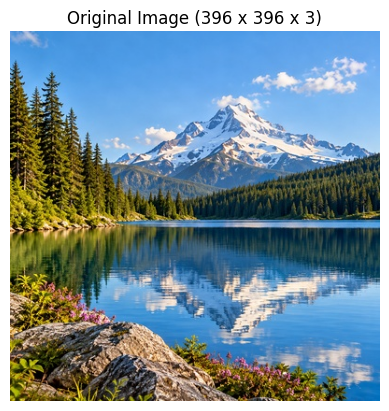

In [2]:
image_path = r'E:\OneDrive - Amrita Vishwa Vidyapeetham- Chennai Campus\5th Semester\ML\ML Lab Activity\Activity 6\landscape_396x396.jpg'   # <-- change this to your own image file name

img = Image.open(image_path).convert('RGB')
print('Loaded user image :', image_path)
img = img.resize((396, 396))
image = np.array(img)

print('Image shape :', image.shape)
plt.imshow(image)
plt.title('Original Image (396 x 396 x 3)')
plt.axis('off')
plt.show()

### Checking the Image Properties

In [3]:
print('Shape            :', image.shape)
print('Data type        :', image.dtype)
print('Pixel value range:', image.min(), 'to', image.max())
print('Total pixels     :', image.shape[0] * image.shape[1])
print('Unique colours   :', len(np.unique(image.reshape(-1, 3), axis=0)))

Shape            : (396, 396, 3)
Data type        : uint8
Pixel value range: 0 to 255
Total pixels     : 156816
Unique colours   : 86446


### Pre-processing: Reshaping the Image into Pixel Data

The image (396, 396, 3) is flattened into a 2-D array of shape (396 x 396, 3) = (156816, 3). Each row is one pixel with its R, G, B values. Values are scaled to the range 0–1.

In [4]:
x = image.reshape(-1, 3) / 255.0
print('Reshaped data shape :', x.shape)

Reshaped data shape : (156816, 3)


### Number of Clusters (K) via Elbow Method

The elbow method is run on a random sample of pixels to keep it fast.

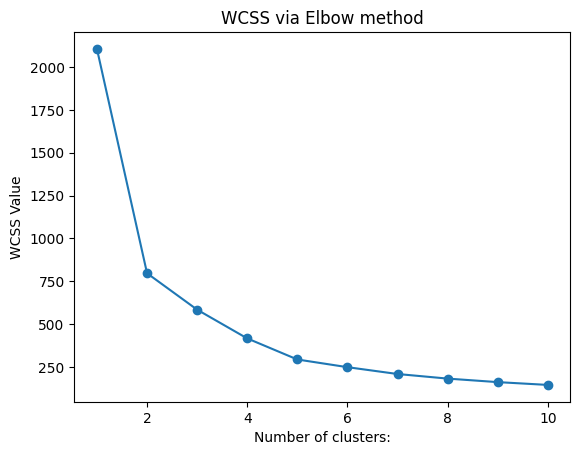

In [5]:
rng = np.random.RandomState(42)
sample_idx = rng.choice(x.shape[0], 10000, replace=False)
x_sample = x[sample_idx]

wcss = []
for i in range(1, 11):
    km = KMeans(n_clusters=i, init='k-means++', random_state=21, n_init=10)
    km.fit(x_sample)
    wcss.append(km.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.title('WCSS via Elbow method')
plt.xlabel('Number of clusters:')
plt.ylabel('WCSS Value')
plt.show()

### K-Means Clustering Training (K = 16 colours)

The model is trained on all pixels. `fit_predict` returns the cluster label of every pixel, and `cluster_centers_` holds the K representative colours.

In [6]:
K = 16
model = KMeans(n_clusters=K, init='k-means++', random_state=42, n_init=10)
labels = model.fit_predict(x)

print('labels shape :', labels.shape)
print('labels       :', labels)
print('\nCluster centres (RGB, 0-255):')
print(np.round(model.cluster_centers_ * 255).astype(int))

labels shape : (156816,)
labels       : [13 13 13 ...  8  8  8]

Cluster centres (RGB, 0-255):
[[156 128 101]
 [122 180 236]
 [ 21  22  11]
 [ 48  95 132]
 [206 179 154]
 [ 71  62  15]
 [ 23  53  61]
 [235 227 222]
 [ 61 128 186]
 [177 157  44]
 [131 154 181]
 [165 196 230]
 [ 83  84  63]
 [ 85 158 228]
 [124 109  28]
 [ 95 117 136]]


### Reconstructing the Compressed Image

Each pixel is replaced by the centroid colour of its cluster.

In [7]:
compressed = model.cluster_centers_[labels]
compressed_image = (compressed * 255).astype(np.uint8).reshape(image.shape)

print('Compressed image shape :', compressed_image.shape)
print('Unique colours now     :', len(np.unique(compressed_image.reshape(-1, 3), axis=0)))

Compressed image shape : (396, 396, 3)
Unique colours now     : 16


### Comparing the Original and Compressed Image

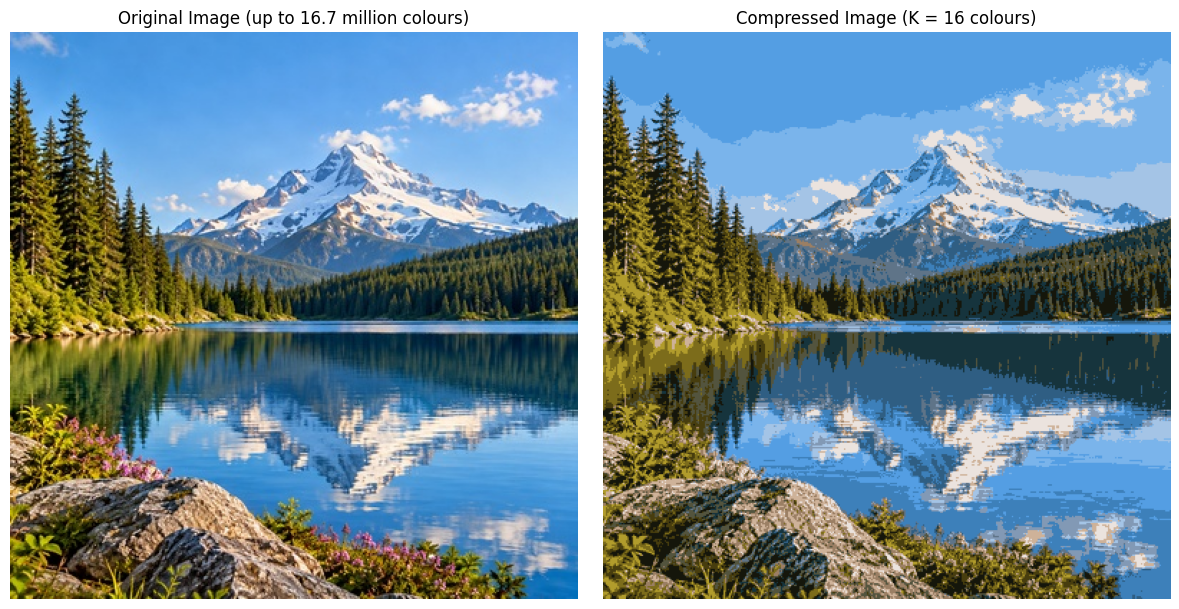

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(image)
ax[0].set_title('Original Image (up to 16.7 million colours)')
ax[0].axis('off')
ax[1].imshow(compressed_image)
ax[1].set_title(f'Compressed Image (K = {K} colours)')
ax[1].axis('off')
plt.tight_layout()
plt.show()

### Evaluation: Compression Ratio and Error

In [9]:
mse = mean_squared_error(image.reshape(-1, 3), compressed_image.reshape(-1, 3))
psnr = 10 * np.log10((255 ** 2) / mse)

original_bits = image.shape[0] * image.shape[1] * 24
bits_per_label = int(np.ceil(np.log2(K)))
compressed_bits = image.shape[0] * image.shape[1] * bits_per_label + K * 24

print('Mean Squared Error (MSE) :', round(mse, 2))
print('PSNR                     :', round(psnr, 2), 'dB')
print('Original size            :', original_bits // 8, 'bytes')
print('Compressed size          :', compressed_bits // 8, 'bytes')
print('Compression ratio        :', round(original_bits / compressed_bits, 2), ': 1')

Mean Squared Error (MSE) : 197.65
PSNR                     : 25.17 dB
Original size            : 470448 bytes
Compressed size          : 78456 bytes
Compression ratio        : 6.0 : 1


### Effect of Different Values of K

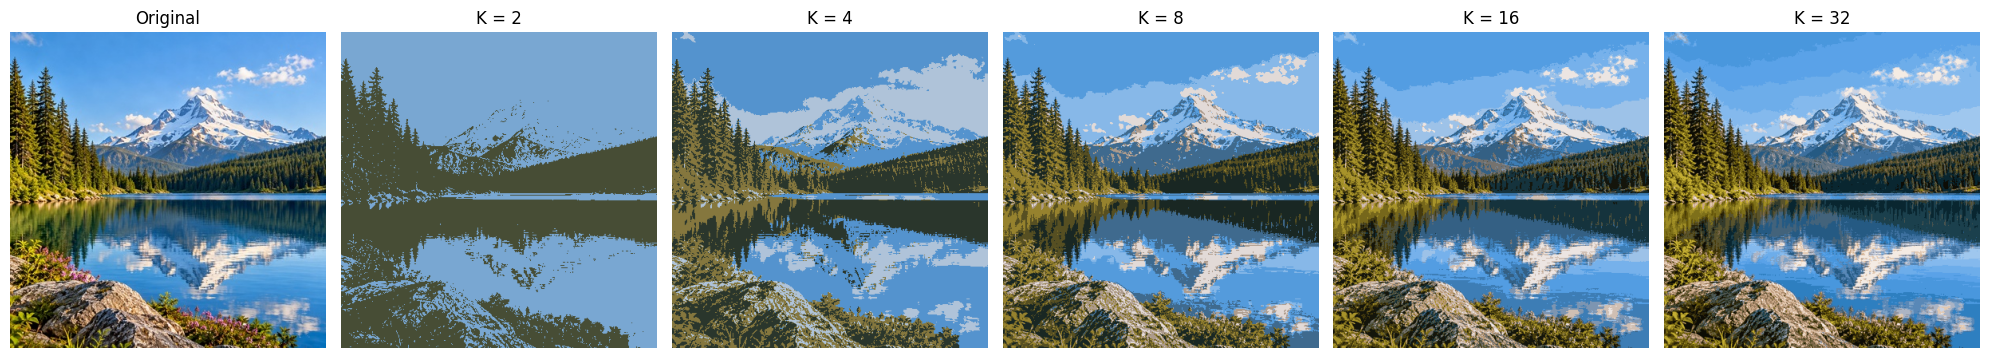

In [10]:
k_values = [2, 4, 8, 16, 32]
fig, ax = plt.subplots(1, len(k_values) + 1, figsize=(20, 4))
ax[0].imshow(image)
ax[0].set_title('Original')
ax[0].axis('off')

for i, k in enumerate(k_values, start=1):
    m = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=4)
    lab = m.fit_predict(x)
    img_k = (m.cluster_centers_[lab] * 255).astype(np.uint8).reshape(image.shape)
    ax[i].imshow(img_k)
    ax[i].set_title(f'K = {k}')
    ax[i].axis('off')

plt.tight_layout()
plt.show()

### Saving the Compressed Image

In [11]:
Image.fromarray(compressed_image).save('compressed_image.png')
print('Saved as compressed_image.png')

Saved as compressed_image.png


### Interpretation

- A 396 x 396 x 3 image is treated as 156,816 data points in RGB colour space, so K-Means (an unsupervised algorithm) can cluster the pixels without any labels.
- The **elbow method** shows the WCSS dropping sharply for small K and flattening afterwards, which indicates that a small number of colours already represents the image well.
- Each cluster centroid is a representative colour. Replacing every pixel by its centroid reduces the image to only **K** distinct colours.
- Storage falls from 24 bits per pixel to only log2(K) bits per pixel (the cluster index) plus a small K-colour palette, giving a large compression ratio.
- Increasing K gives a higher-quality image (lower MSE, higher PSNR) but a lower compression ratio; decreasing K gives stronger compression with visible colour banding. K is therefore a trade-off between image quality and file size.
- Compression here is **lossy**, because the original colours cannot be recovered exactly.